## COSMOS Lab 5: Linear Regression and KNN Regression

**UCLA COSMOS Cluster 10: IoT + Data Science**

This notebook is part of the COSMOS data science lab sequence. Work through the code cells in order and discuss the written prompts with your group.


## Learning Goals

By the end of this lab, you should be able to:

* Review `numpy` including 2-D arrays and array reshaping.
* Use `matplotlib` to make clear exploratory plots.
* Fit simple and multiple linear regression models.
* Use `scikit-learn` with a real IoT sensor dataset.
* Compare linear regression and KNN regression for home appliance energy prediction.
* Explain why feature scaling matters for KNN.


## Table of Contents

* [1 - Review of numpy](#first-bullet)
* [2 - Plotting with matplotlib](#second-bullet)
* [3 - Simple Linear Regression](#third-bullet)
* [4 - Building a model with `sklearn`](#fourth-bullet)
* [5 - Linear regression for appliance energy prediction](#fifth-bullet)
* [6 - K-nearest neighbors regression](#sixth-bullet)


In [1]:
import numpy as np
import scipy as sp
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import pandas as pd
import time
pd.set_option('display.width', 500)
pd.set_option('display.max_columns', 100)
pd.set_option('display.notebook_repr_html', True)
#import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
# Displays the plots for us.
%matplotlib inline

<a class="anchor" id="first-bullet"></a>
## 1 - Review of  the  `numpy` Python library

In lab1 we learned about the `numpy` library [(documentation)](http://www.numpy.org/) and its fast array structure, called the `numpy array`.

In [2]:
# import numpy
import numpy as np

In [3]:
# make an array
my_array = np.array([1,4,9,16])
my_array

array([ 1,  4,  9, 16])

In [4]:
print(f'Size of my array: {my_array.size}, or length of my array: {len(my_array)}')
print (f'Shape of my array: {my_array.shape}')

Size of my array: 4, or length of my array: 4
Shape of my array: (4,)


#### Notice the way the shape appears in numpy arrays

- For a 1D array, .shape returns a tuple with 1 element (n,)
- For a 2D array, .shape returns a tuple with 2 elements (n,m)
- For a 3D array, .shape returns a tuple with 3 elements (n,m,p)

In [5]:
# How to reshape a 1D array to a 2D
my_array.reshape(-1,2)

array([[ 1,  4],
       [ 9, 16]])

Numpy arrays support the same operations as lists! Below we slice and iterate.

In [6]:
print("array[2:4]:", my_array[2:4]) # A slice of the array

# Iterate over the array
for ele in my_array:
    print("element:", ele)

array[2:4]: [ 9 16]
element: 1
element: 4
element: 9
element: 16


Remember `numpy` gains a lot of its efficiency from being **strongly typed** (all elements are of the same type, such as integer or floating point). If the elements of an array are of a different type, `numpy` will force them into the same type (the longest in terms of bytes)

In [7]:
mixed = np.array([1, 2.3, 'eleni', True])
print(type(1), type(2.3), type('eleni'), type(True))
mixed # all elements will become strings

<class 'int'> <class 'float'> <class 'str'> <class 'bool'>


array(['1', '2.3', 'eleni', 'True'], dtype='<U32')

Next, we push ahead to two-dimensional arrays and begin to dive into some of the deeper aspects of `numpy`.

In [8]:
# create a 2d-array by handing a list of lists
my_array2d = np.array([ [1, 2, 3, 4],
                        [5, 6, 7, 8],
                        [9, 10, 11, 12]
])

my_array2d

array([[ 1,  2,  3,  4],
       [ 5,  6,  7,  8],
       [ 9, 10, 11, 12]])

### Array Slicing (a reminder...)

Numpy arrays can be sliced, and can be iterated over with loops.  Below is a schematic illustrating slicing two-dimensional arrays.
A two-dimensional NumPy array can be indexed by row and column using `array[row_slice, column_slice]`.
Notice that the list slicing syntax still works!  
`array[2:,3]` says "in the array, get rows 2 through the end, column 3]"  
`array[3,:]` says "in the array, get row 3, all columns".

### Pandas Slicing (a reminder...)

`.iloc` is by position (position is unique), `.loc` is by label (label is not unique)

In [ ]:
# Build a small IoT-style sensor table for pandas slicing practice.
sensor_log = pd.DataFrame({
    "timestamp": pd.date_range("2026-07-10 13:00", periods=15, freq="10min"),
    "room": ["kitchen", "bedroom", "office", "living"] * 3 + ["kitchen", "bedroom", "office"],
    "temperature_C": [22.1, 21.8, 23.0, 22.5, 22.4, 21.9, 23.2, 22.7, 22.8, 22.0, 23.1, 22.6, 22.9, 22.1, 23.3],
    "humidity_pct": [42, 45, 39, 41, 43, 46, 38, 40, 44, 45, 39, 41, 43, 44, 38],
    "motion_count": [0, 1, 0, 3, 4, 1, 0, 2, 5, 0, 1, 4, 3, 0, 2],
    "appliance_Wh": [35, 30, 25, 60, 95, 40, 30, 70, 110, 35, 45, 85, 75, 30, 65],
})

sensor_log

In [ ]:
# Get rows 10 to 13 using Python slicing style: exclusive of the end.
sensor_log.iloc[10:13]

In [ ]:
# Get columns 0 to 2 for all rows, then show the first few rows.
sensor_log.iloc[:, 0:3].head()

In [ ]:
# Get rows 10 to 13 and only columns 0 to 2.
sensor_log.iloc[10:13, 0:3]

In [ ]:
# Compare with .loc: label slicing is inclusive of the end label.
sensor_log.loc[10:13]

In [ ]:
# Select named columns by label for rows 5 to 10.
sensor_log.loc[5:10, ["timestamp", "room", "appliance_Wh"]]

### Python Trick of the Day

In [15]:
import re
names = ['mayday','springday','horseday','june']

In [16]:

cleaned = []
for name in names:
    this = re.sub('[Dd]ay$', '', name)
    cleaned.append(this)
cleaned

['may', 'spring', 'horse', 'june']

In [17]:
cleaned2 = [re.sub('[Dd]ay$', '', name) for name in names]
cleaned2


['may', 'spring', 'horse', 'june']

In [18]:
# solution
cleaned2 = [re.sub('[Dd]ay$', '', name) for name in names]
cleaned2

['may', 'spring', 'horse', 'june']

<a class="anchor" id="second-bullet"></a>
## 2 - Plotting with matplotlib and beyond
<br>
`matplotlib` is a very powerful `python` library for making scientific plots.

We will not focus too much on the internal aspects of `matplotlib` in today's lab. There are many excellent tutorials out there for `matplotlib`.  For example,
* [`matplotlib` homepage](https://matplotlib.org/)
* [`matplotlib` tutorial](https://github.com/matplotlib/AnatomyOfMatplotlib)

Conveying your findings convincingly is an absolutely crucial part of any analysis. Therefore, you must be able to write well and make compelling visuals.  Creating informative visuals is an involved process and we won't cover that in this lab.  However, part of creating informative data visualizations means generating *readable* figures.  If people can't read your figures or have a difficult time interpreting them, they won't understand the results of your work.  Here are some non-negotiable commandments for any plot:
* Label $x$ and $y$ axes
* Axes labels should be informative
* Axes labels should be large enough to read
* Make tick labels large enough
* Include a legend if necessary
* Include a title if necessary
* Use appropriate line widths
* Use different line styles for different lines on the plot
* Use different markers for different lines

There are other important elements, but that list should get you started on your way.

We will work with `matplotlib` and `seaborn` for plotting in this class.  `matplotlib` is a very powerful `python` library for making scientific plots.  `seaborn` is a little more specialized in that it was developed for statistical data visualization.  We will cover some `seaborn` later in class. In the meantime you can look at the [seaborn documentation](https://seaborn.pydata.org)

First, let's generate some data.

#### Let's plot some functions

We will use the following three functions to make some plots:

* Logistic function:
  \begin{align*}
    f\left(z\right) = \dfrac{1}{1 + be^{-az}}
  \end{align*}
  where $a$ and $b$ are parameters.
* Hyperbolic tangent:
  \begin{align*}
    g\left(z\right) = b\tanh\left(az\right) + c
  \end{align*}
  where $a$, $b$, and $c$ are parameters.
* Rectified Linear Unit:
  \begin{align*}
    h\left(z\right) =
    \left\{
      \begin{array}{lr}
        z, \quad z > 0 \\
        \epsilon z, \quad z\leq 0
      \end{array}
    \right.
  \end{align*}
  where $\epsilon < 0$ is a small, positive parameter.

You are given the code for the first two functions.  Notice that $z$ is passed in as a `numpy` array and that the functions are returned as `numpy` arrays.  Parameters are passed in as floats.

You should write a function to compute the rectified linear unit.  The input should be a `numpy` array for $z$ and a positive float for $\epsilon$.

In [19]:
import numpy as np

def logistic(z: np.ndarray, a: float, b: float) -> np.ndarray:
    """ Compute logistic function
      Inputs:
         a: exponential parameter
         b: exponential prefactor
         z: numpy array; domain
      Outputs:
         f: numpy array of floats, logistic function
    """

    den = 1.0 + b * np.exp(-a * z)
    return 1.0 / den

def stretch_tanh(z: np.ndarray, a: float, b: float, c: float) -> np.ndarray:
    """ Compute stretched hyperbolic tangent
      Inputs:
         a: horizontal stretch parameter (a>1 implies a horizontal squish)
         b: vertical stretch parameter
         c: vertical shift parameter
         z: numpy array; domain
      Outputs:
         g: numpy array of floats, stretched tanh
    """
    return b * np.tanh(a * z) + c

def relu(z: np.ndarray, eps: float = 0.01) -> np.ndarray:
    """ Compute rectificed linear unit
      Inputs:
         eps: small positive parameter
         z: numpy array; domain
      Outputs:
         h: numpy array; relu
    """
    return np.fmax(z, eps * z)

Now let's make some plots.  First, let's just warm up and plot the logistic function.

In [20]:
x = np.linspace(-5.0, 5.0, 100) # Equally spaced grid of 100 pts between -5 and 5

f = logistic(x, 1.0, 1.0) # Generate data

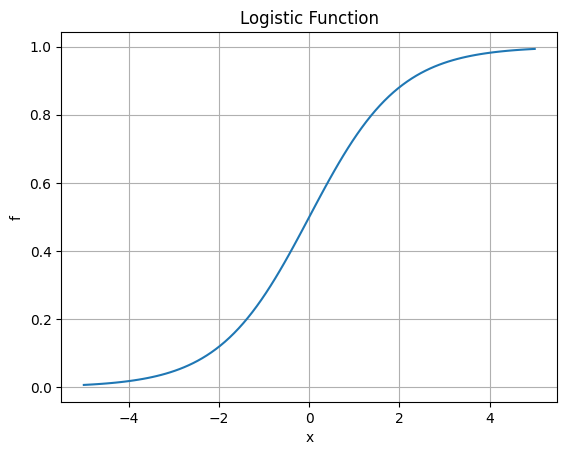

In [21]:
plt.plot(x, f)
plt.xlabel('x')
plt.ylabel('f')
plt.title('Logistic Function')
plt.grid(True)

#### Figures with subplots

Let's start thinking about the plots as objects. We have the `figure` object which is like a matrix of smaller plots named `axes`. You can use array notation when handling it.

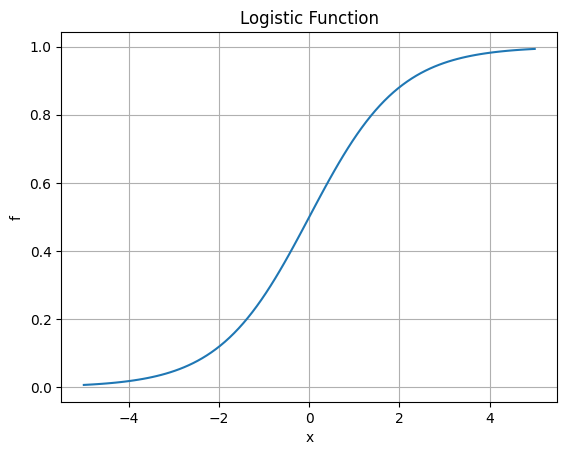

In [22]:
fig, ax = plt.subplots(1,1) # Get figure and axes objects

ax.plot(x, f) # Make a plot

# Create some labels
ax.set_xlabel('x')
ax.set_ylabel('f')
ax.set_title('Logistic Function')

# Grid
ax.grid(True)

Wow, it's *exactly* the same plot!  Notice, however, the use of `ax.set_xlabel()` instead of `plt.xlabel()`.  The difference is tiny, but you should be aware of it.  I will use this plotting syntax from now on.

What else do we need to do to make this figure better?  Here are some options:
* Make labels bigger!
* Make line fatter
* Make tick mark labels bigger
* Make the grid less pronounced
* Make figure bigger

Let's get to it.

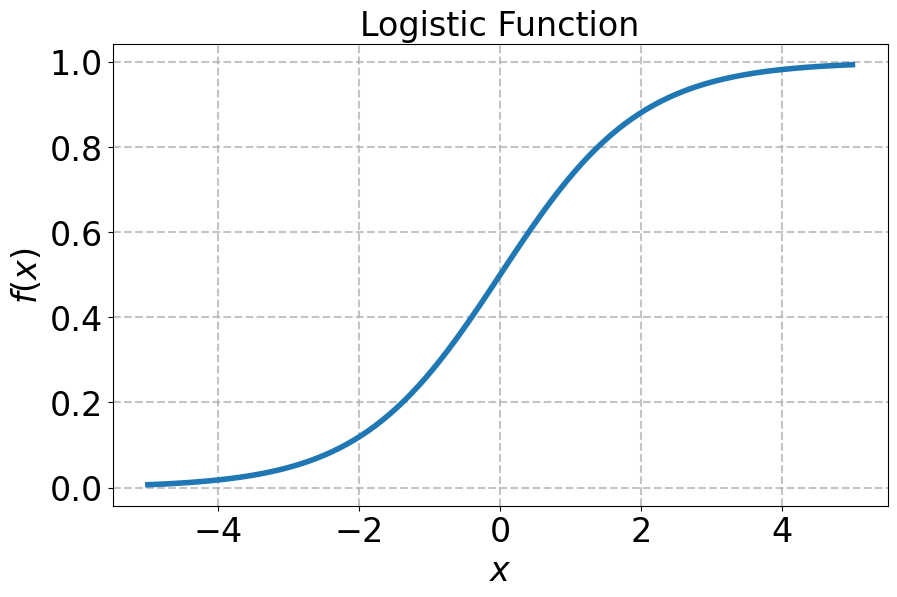

In [23]:
fig, ax = plt.subplots(1,1, figsize=(10,6)) # Make figure bigger

# Make line plot
ax.plot(x, f, lw=4)

# Update ticklabel size
ax.tick_params(labelsize=24)

# Make labels
ax.set_xlabel(r'$x$', fontsize=24) # Use TeX for mathematical rendering
ax.set_ylabel(r'$f(x)$', fontsize=24) # Use TeX for mathematical rendering
ax.set_title('Logistic Function', fontsize=24)

ax.grid(True, lw=1.5, ls='--', alpha=0.75)

Notice:
* `lw` stands for `linewidth`.  We could also write `ax.plot(x, f, linewidth=4)`
* `ls` stands for `linestyle`.
* `alpha` stands for transparency.

The only thing remaining to do is to change the $x$ limits.  Clearly these should go from $-5$ to $5$.

In [24]:
#fig.savefig('logistic.png')

# Put this in a markdown cell and uncomment this to check what you saved.
# ![](logistic.png)

#### Resources
If you want to see all the styles available, please take a look at the documentation.
* [Line styles](https://matplotlib.org/2.0.1/api/lines_api.html#matplotlib.lines.Line2D.set_linestyle)
* [Marker styles](https://matplotlib.org/2.0.1/api/markers_api.html#module-matplotlib.markers)
* [Everything you could ever want](https://matplotlib.org/2.0.1/api/lines_api.html#matplotlib.lines.Line2D.set_marker)

We haven't discussed it yet, but you can also put a legend on a figure.  You'll do that in the next exercise.  Here are some additional resources:
* [Legend](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.legend.html)
* [Grid](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.grid.html)

`ax.legend(loc='best', fontsize=24);`

<div class="exercise"><b>Exercise</b></div>

Do the following:
* Make a figure with the logistic function, hyperbolic tangent, and rectified linear unit.
* Use different line styles for each plot
* Put a legend on your figure

Your result should show three clearly labeled curves with a legend.

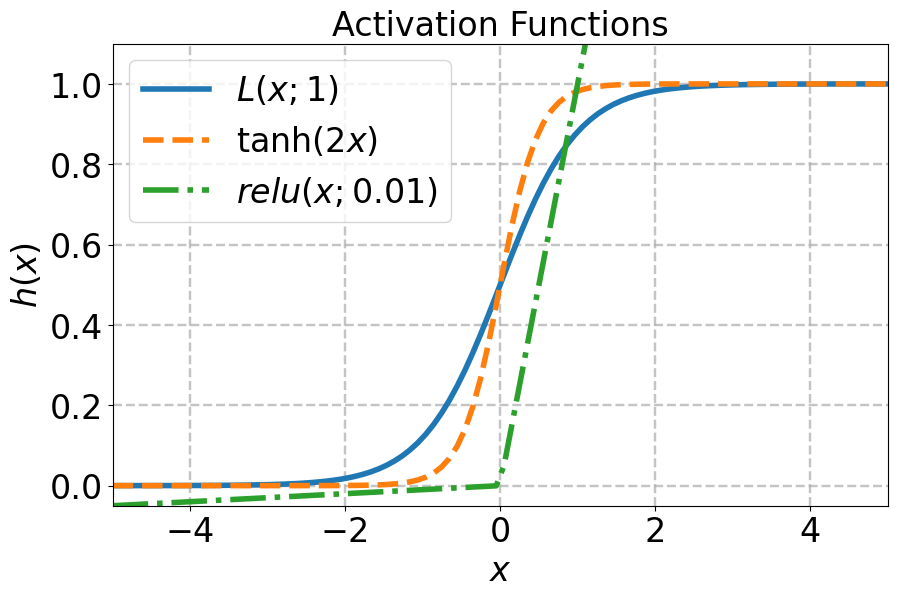

In [25]:

# First get the data
f = logistic(x, 2.0, 1.0)
g = stretch_tanh(x, 2.0, 0.5, 0.5)
h = relu(x)

fig, ax = plt.subplots(1,1, figsize=(10,6)) # Create figure object

# Make actual plots
# (Notice the label argument!)
ax.plot(x, f, lw=4, ls='-', label=r'$L(x;1)$')
ax.plot(x, g, lw=4, ls='--', label=r'$\tanh(2x)$')
ax.plot(x, h, lw=4, ls='-.', label=r'$relu(x; 0.01)$')

# Make the tick labels readable
ax.tick_params(labelsize=24)

# Set axes limits to make the scale nice
ax.set_xlim(x.min(), x.max())
ax.set_ylim(h.min(), 1.1)

# Make readable labels
ax.set_xlabel(r'$x$', fontsize=24)
ax.set_ylabel(r'$h(x)$', fontsize=24)
ax.set_title('Activation Functions', fontsize=24)

# Set up grid
ax.grid(True, lw=1.75, ls='--', alpha=0.75)

# Put legend on figure
ax.legend(loc='best', fontsize=24);

fig.savefig('nice_plots.png')

<div class="exercise"><b>Exercise</b></div>

These figures look nice in the plot and it makes sense for comparison. Now let's put the 3 different figures in separate plots.

* Make a separate plot for each figure and line them up on the same row.

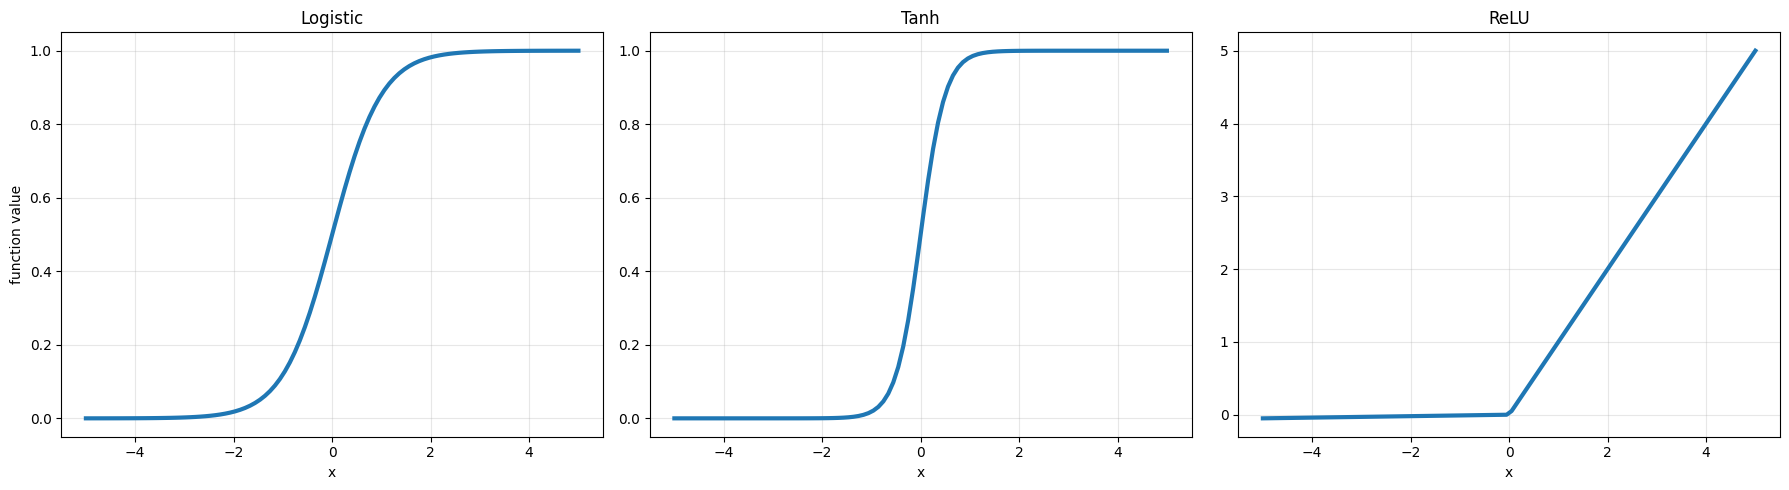

In [26]:
f = logistic(x, 2.0, 1.0)
g = stretch_tanh(x, 2.0, 0.5, 0.5)
h = relu(x)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, y, title in zip(axes, [f, g, h], ['Logistic', 'Tanh', 'ReLU']):
    ax.plot(x, y, lw=3)
    ax.set_title(title)
    ax.set_xlabel('x')
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('function value')
fig.tight_layout()
fig.savefig('nice_sub_plots.png')


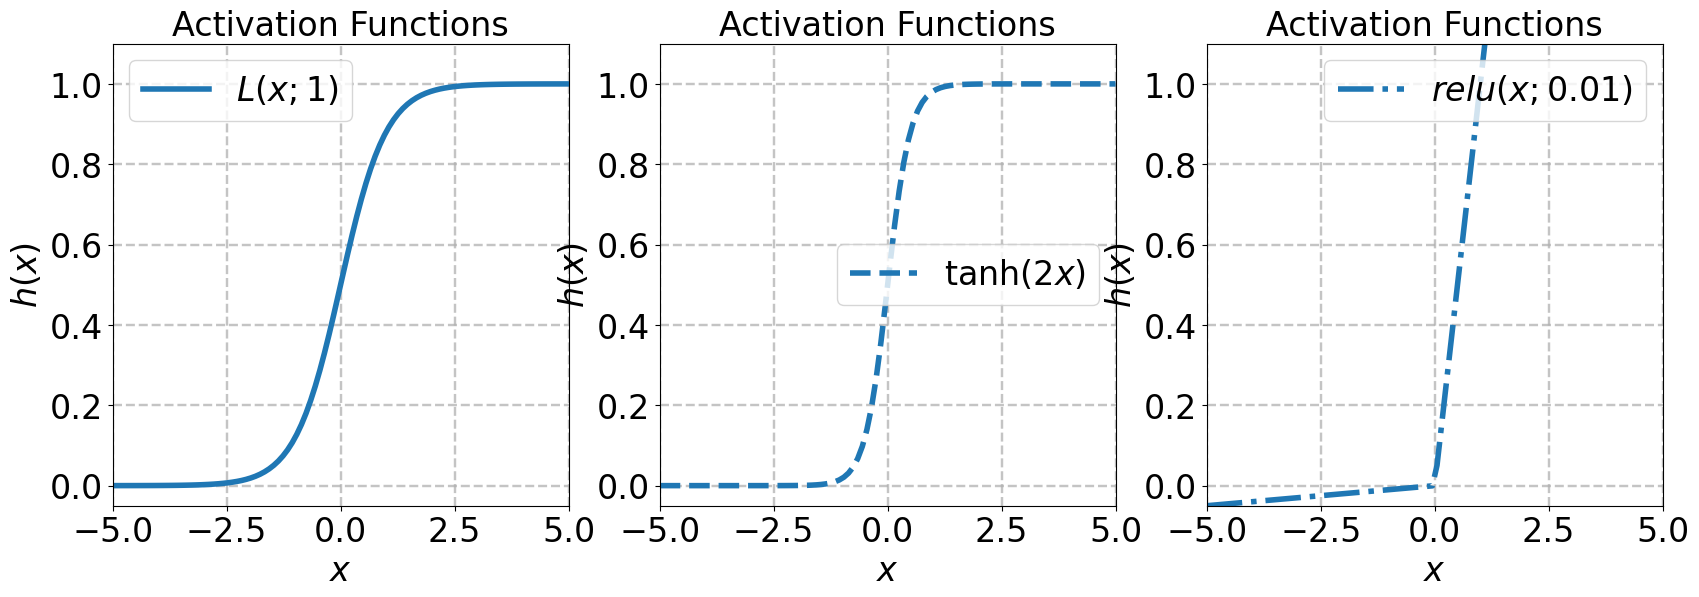

In [27]:
# Reference solution originally loaded from three_subplots.py
# First get the data
f = logistic(x, 2.0, 1.0)
g = stretch_tanh(x, 2.0, 0.5, 0.5)
h = relu(x)

fig, ax = plt.subplots(1,3, figsize=(20,6)) # Create figure object

# Make actual plots
ax[0].plot(x, f, lw=4, ls='-', label=r'$L(x;1)$')
ax[1].plot(x, g, lw=4, ls='--', label=r'$\tanh(2x)$')
ax[2].plot(x, h, lw=4, ls='-.', label=r'$relu(x; 0.01)$')

# Make the tick labels readable
ax[0].tick_params(labelsize=24)
ax[1].tick_params(labelsize=24)
ax[2].tick_params(labelsize=24)

# Set axes limits to make the scale nice
ax[0].set_xlim(x.min(), x.max())
ax[0].set_ylim(h.min(), 1.1)
ax[1].set_xlim(x.min(), x.max())
ax[1].set_ylim(h.min(), 1.1)
ax[2].set_xlim(x.min(), x.max())
ax[2].set_ylim(h.min(), 1.1)

# Make readable labels
ax[0].set_xlabel(r'$x$', fontsize=24)
ax[0].set_ylabel(r'$h(x)$', fontsize=24)
ax[0].set_title('Activation Functions', fontsize=24)

ax[1].set_xlabel(r'$x$', fontsize=24)
ax[1].set_ylabel(r'$h(x)$', fontsize=24)
ax[1].set_title('Activation Functions', fontsize=24)

ax[2].set_xlabel(r'$x$', fontsize=24)
ax[2].set_ylabel(r'$h(x)$', fontsize=24)
ax[2].set_title('Activation Functions', fontsize=24)

# Set up grid
ax[0].grid(True, lw=1.75, ls='--', alpha=0.75)
ax[1].grid(True, lw=1.75, ls='--', alpha=0.75)
ax[2].grid(True, lw=1.75, ls='--', alpha=0.75)

# Put legend on figure
ax[0].legend(loc='best', fontsize=24);
ax[1].legend(loc='best', fontsize=24);
ax[2].legend(loc='best', fontsize=24);

#fig.savefig('nice_sub_plots.png')


<div class="exercise"><b>Exercise</b></div>

* Make a grid of 2 x 3 separate plots, 3 will be empty. Just plot the functions and do not worry about cosmetics. We just want you ro see the functionality.

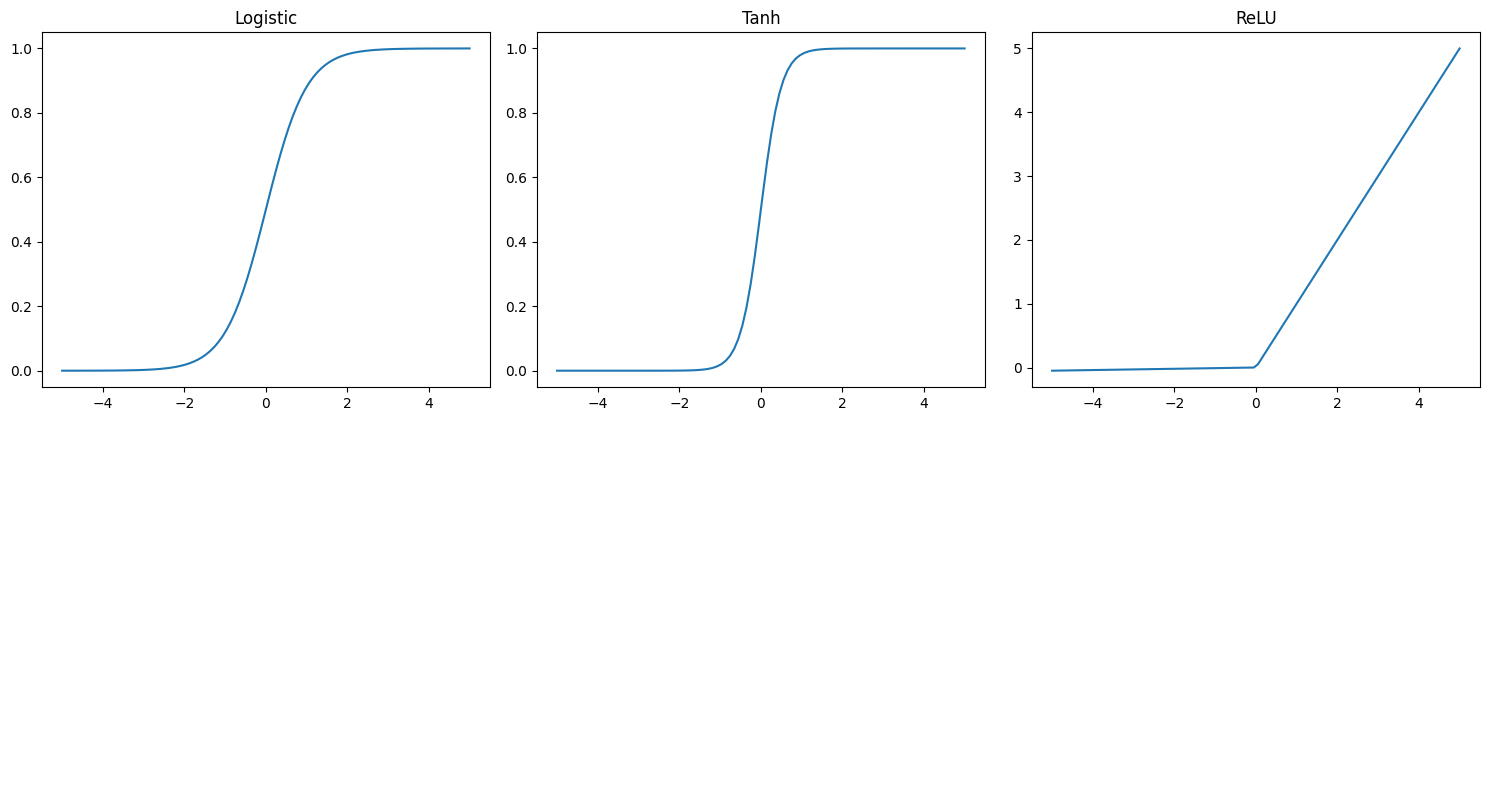

In [28]:
f = logistic(x, 2.0, 1.0)
g = stretch_tanh(x, 2.0, 0.5, 0.5)
h = relu(x)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, y, title in zip(axes[:3], [f, g, h], ['Logistic', 'Tanh', 'ReLU']):
    ax.plot(x, y)
    ax.set_title(title)
for ax in axes[3:]:
    ax.axis('off')
fig.tight_layout()


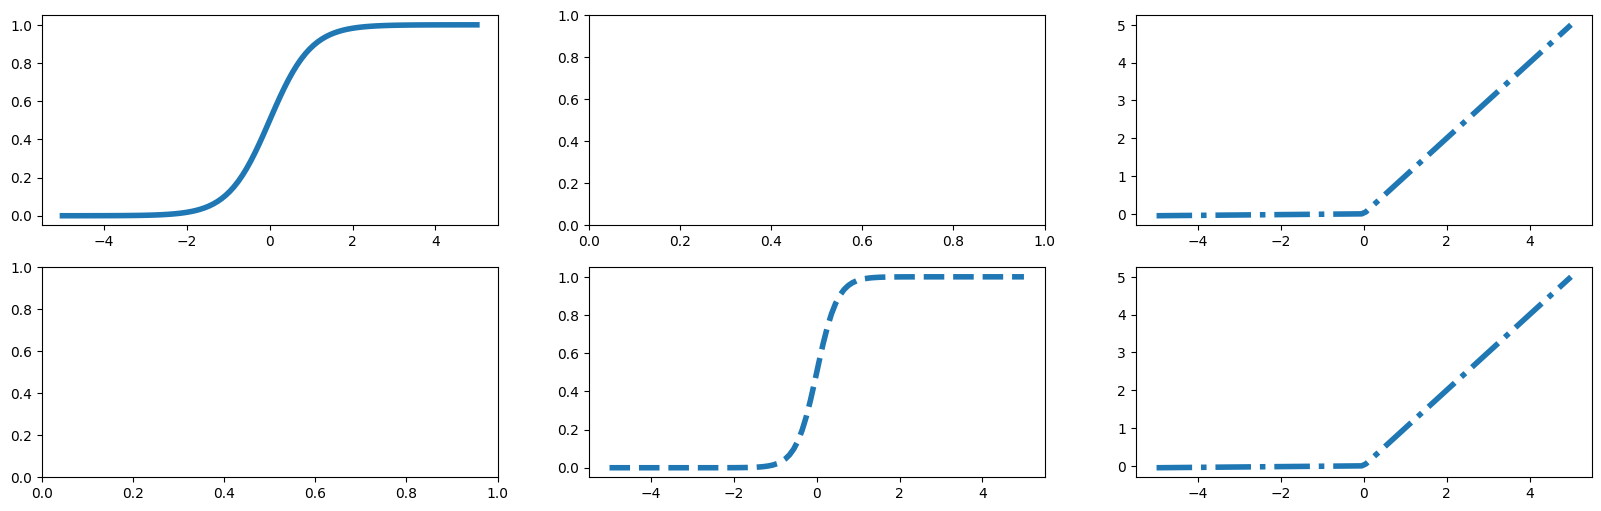

In [29]:
# Reference solution originally loaded from six_subplots.py

# First get the data
f = logistic(x, 2.0, 1.0)
g = stretch_tanh(x, 2.0, 0.5, 0.5)
h = relu(x)

fig, ax = plt.subplots(2,3, figsize=(20,6)) # Create figure object

# Make actual plots
ax[0][0].plot(x, f, lw=4, ls='-', label=r'$L(x;1)$')
ax[1][1].plot(x, g, lw=4, ls='--', label=r'$\tanh(2x)$')
ax[1][2].plot(x, h, lw=4, ls='-.', label=r'$relu(x; 0.01)$')
ax[0][2].plot(x, h, lw=4, ls='-.', label=r'$relu(x; 0.01)$')


<a class="anchor" id="third-bullet"></a>
## 3 - Simple Linear Regression

Linear regression and its many extensions are a workhorse of the statistics and data science community, both in application and as a reference point for other models. Most of the major concepts in machine learning can be and often are discussed in terms of various linear regression models. Thus, this section will introduce you to building and fitting linear regression models and some of the process behind it, so that you can 1) fit models to data you encounter 2) experiment with different kinds of linear regression and observe their effects 3) see some of the technology that makes regression models work.


### Linear regression with a toy dataset
We first examine a toy problem, focusing our efforts on fitting a linear model to a small dataset with three observations.  Each observation consists of one predictor $x_i$ and one response $y_i$ for $i = 1, 2, 3$,

\begin{align*}
(x , y) = \{(x_1, y_1), (x_2, y_2), (x_3, y_3)\}.
\end{align*}

To be very concrete, let's set the values of the predictors and responses.

\begin{equation*}
(x , y) = \{(1, 2), (2, 2), (3, 4)\}
\end{equation*}

There is no line of the form $\beta_0 + \beta_1 x = y$ that passes through all three observations, since the data are not collinear. Thus our aim is to find the line that best fits these observations in the *least-squares sense*, as discussed in lecture.

<div class="exercise"><b>Exercise (optional practice)</b></div>

* Make two numpy arrays out of this data, x_train and y_train
* Check the dimensions of these arrays
* Try to reshape them into a different shape
* Make points into a very simple scatterplot
* Make a better scatterplot

(3,) (3,)
(3, 1)


Text(0.5, 1.0, 'Toy Training Data')

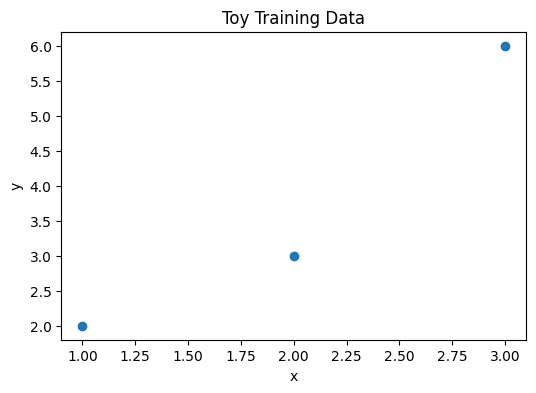

In [30]:
x_train = np.array([1, 2, 3])
y_train = np.array([2, 3, 6])
print(x_train.shape, y_train.shape)
print(x_train.reshape(-1, 1).shape)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.scatter(x_train, y_train)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Toy Training Data')


In [31]:
# solution
x_train = np.array([1,2,3])
y_train = np.array([2,3,6])
type(x_train)

numpy.ndarray

In [32]:
x_train.shape

(3,)

In [33]:
x_train = x_train.reshape(3,1)
x_train.shape

(3, 1)

(3, 1) (3,)


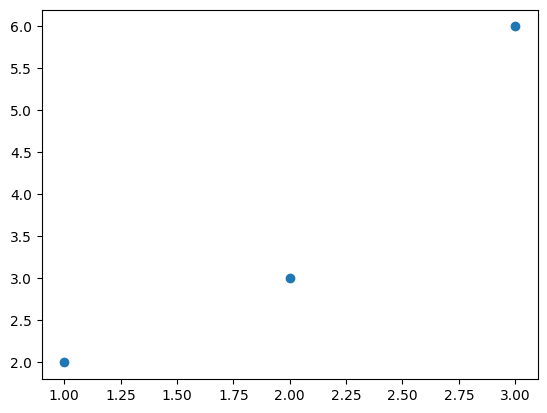

In [34]:
# Reference solution originally loaded from simple_scatterplot.py
# Make a simple scatterplot
plt.scatter(x_train,y_train)

# check dimensions
print(x_train.shape,y_train.shape)


<Axes: title={'center': 'hello nice plot'}, xlabel='$x$', ylabel='$y$'>

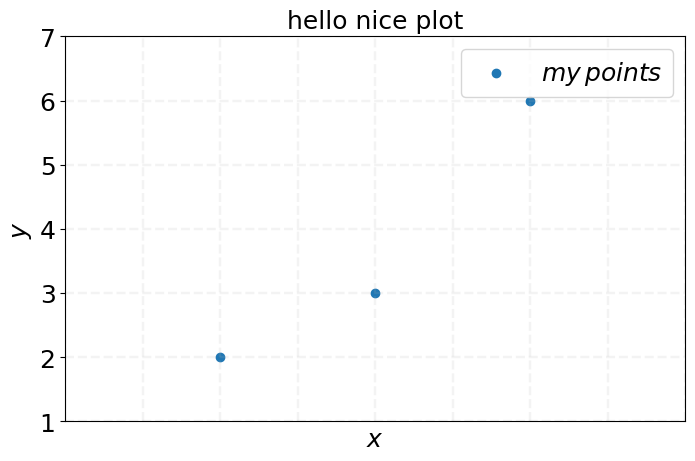

In [35]:
# Reference solution originally loaded from nice_scatterplot.py
def nice_scatterplot(x, y, title):
    # font size
    f_size = 18

    # make the figure
    fig, ax = plt.subplots(1,1, figsize=(8,5)) # Create figure object

    # set axes limits to make the scale nice
    ax.set_xlim(np.min(x)-1, np.max(x) + 1)
    ax.set_ylim(np.min(y)-1, np.max(y) + 1)

    # adjust size of tickmarks in axes
    ax.tick_params(labelsize = f_size)

    # remove tick labels
    ax.tick_params(labelbottom=False,  bottom=False)

    # adjust size of axis label
    ax.set_xlabel(r'$x$', fontsize = f_size)
    ax.set_ylabel(r'$y$', fontsize = f_size)

    # set figure title label
    ax.set_title(title, fontsize = f_size)

    # you may set up grid with this
    ax.grid(True, lw=1.75, ls='--', alpha=0.15)

    # make actual plot (Notice the label argument!)
    #ax.scatter(x, y, label=r'$my points$')
    #ax.scatter(x, y, label='$my points$')
    ax.scatter(x, y, label=r'$my\,points$')
    ax.legend(loc='best', fontsize = f_size);

    return ax

nice_scatterplot(x_train, y_train, 'hello nice plot')



#### Formulae
Linear regression is special among the models we study because it can be solved explicitly. While most other models (and even some advanced versions of linear regression) must be solved itteratively, linear regression has a formula where you can simply plug in the data.

For the single predictor case it is:
    \begin{align}
      \beta_1 &= \frac{\sum_{i=1}^n{(x_i-\bar{x})(y_i-\bar{y})}}{\sum_{i=1}^n{(x_i-\bar{x})^2}}\\
      \beta_0 &= \bar{y} - \beta_1\bar{x}\
    \end{align}
    
Where $\bar{y}$ and $\bar{x}$ are the mean of the y values and the mean of the x values, respectively.

###  Building a model from scratch
In this part, we will solve the equations for simple linear regression and find the best fit solution to our toy problem.

The snippets of code below implement the linear regression equations on the observed predictors and responses, which we'll call the training data set.  Let's walk through the code.

We have to reshape our arrrays to 2D. We will see later why.

<div class="exercise"><b>Exercise</b></div>

* make an array with shape (2,3)
* reshape it to a size that you want

In [36]:
xx = np.array([[1, 2, 3], [4, 6, 8]])
reshaped = xx.reshape(3, 2)
print(xx.shape, reshaped.shape)
reshaped


(2, 3) (3, 2)


array([[1, 2],
       [3, 4],
       [6, 8]])

In [37]:
#solution
xx = np.array([[1,2,3],[4,6,8]])
xxx = xx.reshape(-1,2)
xxx.shape

(3, 2)

In [38]:
# Reshape to be a proper 2D array
x_train = x_train.reshape(x_train.shape[0], 1)
y_train = y_train.reshape(y_train.shape[0], 1)

print(x_train.shape)

(3, 1)


In [39]:
# first, compute means
y_bar = np.mean(y_train)
x_bar = np.mean(x_train)

# build the two terms
numerator = np.sum( (x_train - x_bar)*(y_train - y_bar) )
denominator = np.sum((x_train - x_bar)**2)

print(numerator.shape, denominator.shape) #check shapes

() ()


* Why the empty brackets? (The numerator and denominator are scalars, as expected.)

In [40]:
#slope beta1
beta_1 = numerator/denominator

#intercept beta0
beta_0 = y_bar - beta_1*x_bar

print("The best-fit line is {0:3.2f} + {1:3.2f} * x".format(beta_0, beta_1))
print(f'The best fit is {beta_0}')

The best-fit line is -0.33 + 2.00 * x
The best fit is -0.3333333333333335


<div class="exercise"><b>Exercise</b></div>

Turn the code from the above cells into a function called `simple_linear_regression_fit`, that inputs the training data and returns `beta0` and `beta1`.

To do this, copy and paste the code from the above cells below and adjust the code as needed, so that the training data becomes the input and the betas become the output.

```python
def simple_linear_regression_fit(x_train: np.ndarray, y_train: np.ndarray) -> np.ndarray:
    
    return
```

Check your function by calling it with the training data from above and printing out the beta values.

In [41]:
def simple_linear_regression_fit(x_train: np.ndarray, y_train: np.ndarray) -> np.ndarray:
    if len(x_train.shape) < 2:
        x_train = x_train.reshape(x_train.shape[0], 1)
    if len(y_train.shape) < 2:
        y_train = y_train.reshape(y_train.shape[0], 1)

    y_bar = np.mean(y_train)
    x_bar = np.mean(x_train)
    numerator = np.sum((x_train - x_bar) * (y_train - y_bar))
    denominator = np.sum((x_train - x_bar) ** 2)
    beta_1 = numerator / denominator
    beta_0 = y_bar - beta_1 * x_bar
    return np.array([beta_0, beta_1])

beta_0, beta_1 = simple_linear_regression_fit(x_train, y_train)
print(beta_0, beta_1)


-0.3333333333333335 2.0


In [42]:
# Reference solution originally loaded from simple_linear_regression_fit.py
def simple_linear_regression_fit(x_train: np.ndarray, y_train: np.ndarray) -> np.ndarray:
    """
    Inputs:
    x_train: a (num observations by 1) array holding the values of the predictor variable
    y_train: a (num observations by 1) array holding the values of the response variable

    Returns:
    beta_vals:  a (num_features by 1) array holding the intercept and slope coeficients
    """

    # Check input array sizes
    if len(x_train.shape) < 2:
        print("Reshaping features array.")
        x_train = x_train.reshape(x_train.shape[0], 1)

    if len(y_train.shape) < 2:
        print("Reshaping observations array.")
        y_train = y_train.reshape(y_train.shape[0], 1)

    # first, compute means
    y_bar = np.mean(y_train)
    x_bar = np.mean(x_train)

    # build the two terms
    numerator = np.sum( (x_train - x_bar)*(y_train - y_bar) )
    denominator = np.sum((x_train - x_bar)**2)

    #slope beta1
    beta_1 = numerator/denominator

    #intercept beta0
    beta_0 = y_bar - beta_1*x_bar

    return np.array([beta_0,beta_1])


* Let's run this function and see the coefficients

In [43]:
x_train = np.array([1 ,2, 3])
y_train = np.array([2, 2, 4])

betas = simple_linear_regression_fit(x_train, y_train)

beta_0 = betas[0]
beta_1 = betas[1]

print("The best-fit line is {0:8.6f} + {1:8.6f} * x".format(beta_0, beta_1))

Reshaping features array.
Reshaping observations array.
The best-fit line is 0.666667 + 1.000000 * x


<div class="exercise"><b>Exercise</b></div>

* Do the values of `beta0` and `beta1` seem reasonable?
* Plot the training data using a scatter plot.
* Plot the best fit line with `beta0` and `beta1` together with the training data.

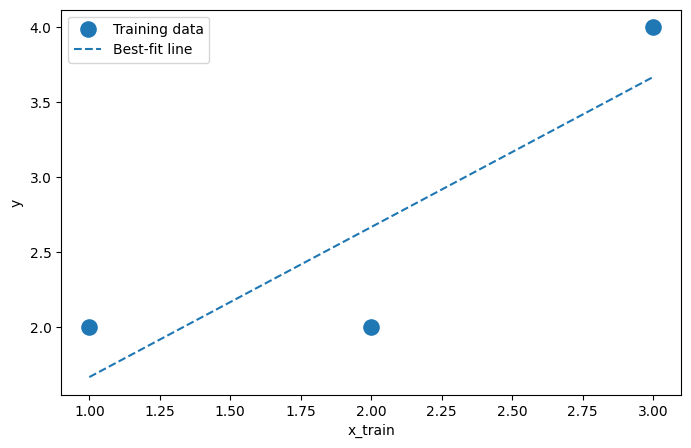

In [44]:
fig_scat, ax_scat = plt.subplots(1, 1, figsize=(8, 5))
x_plot = np.array([[1, 2, 3]]).T
best_fit = beta_0 + beta_1 * x_plot
ax_scat.scatter(x_plot, y_train, s=120, label='Training data')
ax_scat.plot(x_plot, best_fit, ls='--', label='Best-fit line')
ax_scat.set_xlabel('x_train')
ax_scat.set_ylabel('y')
ax_scat.legend()


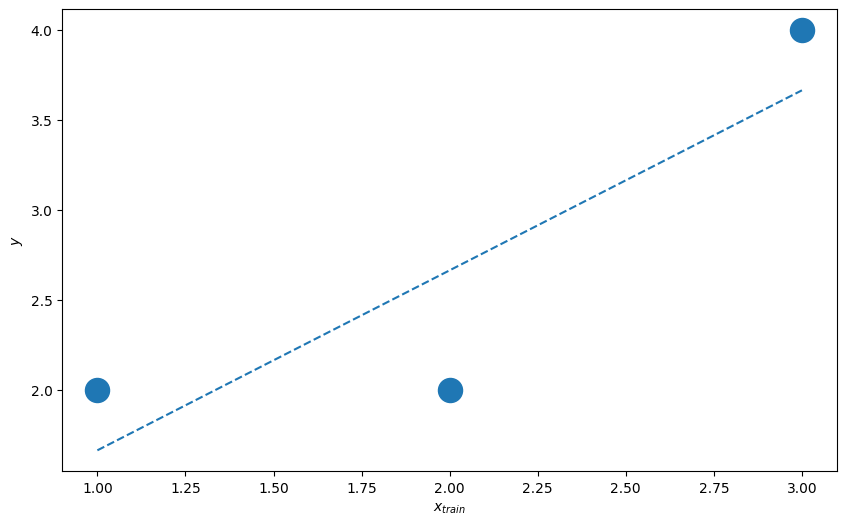

In [45]:
# Reference solution originally loaded from best_fit_scatterplot.py
fig_scat, ax_scat = plt.subplots(1,1, figsize=(10,6))

# Plot best-fit line
x_train = np.array([[1, 2, 3]]).T

best_fit = beta_0 + beta_1 * x_train

ax_scat.scatter(x_train, y_train, s=300, label='Training Data')
ax_scat.plot(x_train, best_fit, ls='--', label='Best Fit Line')

ax_scat.set_xlabel(r'$x_{train}$')
ax_scat.set_ylabel(r'$y$');


The values of `beta0` and `beta1` seem roughly reasonable.  They capture the positive correlation.  The line does appear to be trying to get as close as possible to all the points.

<a class="anchor" id="fourth-bullet"></a>
## 4 - Building a model with `sklearn`

Now that we can fit a small linear regression example from scratch, we will use `scikit-learn` on a real IoT dataset. `scikit-learn` expects:

* `X`: a 2-D feature matrix, with one row per observation and one column per feature.
* `y`: a 1-D target vector, with one value per observation.

The task for this lab is to predict home appliance energy use from environmental sensor measurements.


### Practice with `sklearn` and an IoT energy dataset

We will use `energydata_complete.csv`, an appliance energy prediction dataset collected from a house with temperature, humidity, weather, and light measurements. Each row is a 10-minute measurement window. The target variable is:

* `Appliances`: appliance energy use in Wh for that 10-minute window.

The prediction problem is realistic: a home IoT system can observe temperature, humidity, light, and outdoor weather, but appliance use depends on human behavior too. Do not expect perfect predictions.


In [83]:
from pathlib import Path
import os

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

candidate_paths = [
    Path("energydata_complete.csv"),
    Path("../../IoT_Dataset/energydata_complete.csv"),
    Path("../IoT_Dataset/energydata_complete.csv"),
    Path("../../../../COSMOS_Labs/IoT_Dataset/energydata_complete.csv"),
    Path("COSMOS_Labs/IoT_Dataset/energydata_complete.csv"),
]

data_path = next((path for path in candidate_paths if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Could not find energydata_complete.csv. Put it in this notebook folder "
        "or in COSMOS_Labs/IoT_Dataset/."
    )

energy = pd.read_csv(data_path, parse_dates=["date"])
energy = energy.sort_values("date").reset_index(drop=True)
energy.head()


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [84]:
print(f"Rows: {energy.shape[0]:,}")
print(f"Columns: {energy.shape[1]}")
print(f"Date range: {energy['date'].min()} to {energy['date'].max()}")
print(f"Missing values: {energy.isna().sum().sum()}")

energy[["date", "Appliances", "lights", "T1", "RH_1", "T_out", "RH_out", "Windspeed"]].head()


Rows: 19,735
Columns: 29
Date range: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Missing values: 0


,date,Appliances,lights,T1,RH_1,T_out,RH_out,Windspeed
0,2016-01-11 17:00:00,60,30,19.89,47.596667,6.600000,92.0,7.000000
1,2016-01-11 17:10:00,60,30,19.89,46.693333,6.483333,92.0,6.666667
2,2016-01-11 17:20:00,50,30,19.89,46.300000,6.366667,92.0,6.333333
3,2016-01-11 17:30:00,50,40,19.89,46.066667,6.250000,92.0,6.000000
4,2016-01-11 17:40:00,60,40,19.89,46.333333,6.133333,92.0,5.666667


### Feature engineering

The columns named `T1` through `T9` are indoor temperature measurements from different rooms. The columns named `RH_1` through `RH_9` are relative humidity measurements. Outdoor weather is captured by variables such as `T_out`, `RH_out`, `Windspeed`, `Visibility`, and `Tdewpoint`.

We will add simple time features from the timestamp. We will exclude `rv1` and `rv2` because those are random variables included in the original dataset, not physical IoT sensor readings.


In [85]:
energy["hour"] = energy["date"].dt.hour
energy["day_of_week"] = energy["date"].dt.dayofweek
energy["is_weekend"] = (energy["day_of_week"] >= 5).astype(int)

target = "Appliances"
feature_columns = [
    col for col in energy.columns
    if col not in ["date", target, "rv1", "rv2"]
]

print(f"Target: {target}")
print(f"Number of features: {len(feature_columns)}")
print(feature_columns)


Target: Appliances
Number of features: 28
['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'hour', 'day_of_week', 'is_weekend']


In [86]:
energy[[target] + feature_columns].describe().T[["mean", "std", "min", "max"]].head(12)


,mean,std,min,max
Appliances,97.694958,102.524891,10.000000,1080.000000
lights,3.801875,7.935988,0.000000,70.000000
T1,21.686571,1.606066,16.790000,26.260000
RH_1,40.259739,3.979299,27.023333,63.360000
T2,20.341219,2.192974,16.100000,29.856667
RH_2,40.420420,4.069813,20.463333,56.026667
T3,22.267611,2.006111,17.200000,29.236000
RH_3,39.242500,3.254576,28.766667,50.163333
T4,20.855335,2.042884,15.100000,26.200000
RH_4,39.026904,4.341321,27.660000,51.090000


### Exploratory plots

Before fitting a model, inspect the target. Appliance energy use is often bursty: many time windows have low energy use, with occasional larger spikes.


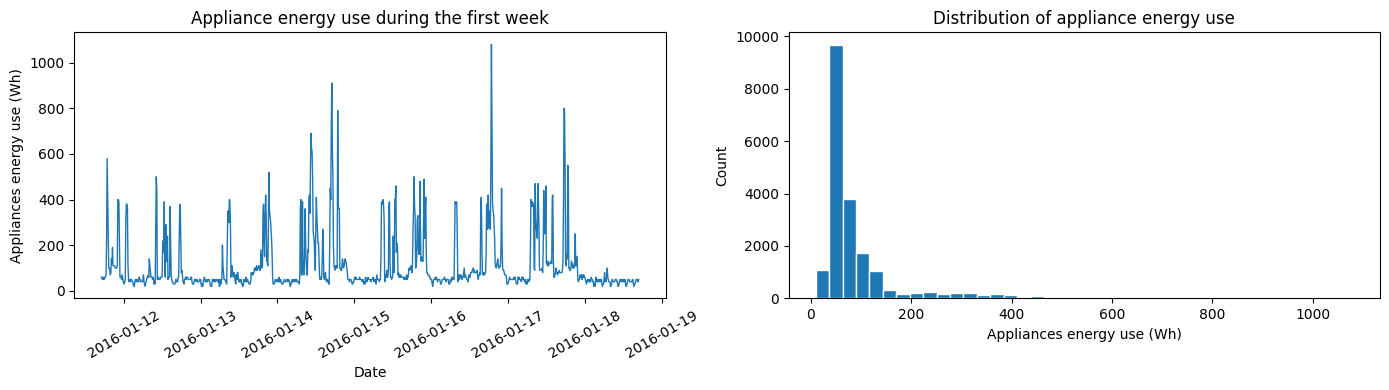

In [87]:
one_week = energy.iloc[:7 * 24 * 6]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(one_week["date"], one_week[target], linewidth=1)
axes[0].set_title("Appliance energy use during the first week")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Appliances energy use (Wh)")
axes[0].tick_params(axis="x", rotation=30)

axes[1].hist(energy[target], bins=40, edgecolor="white")
axes[1].set_title("Distribution of appliance energy use")
axes[1].set_xlabel("Appliances energy use (Wh)")
axes[1].set_ylabel("Count")

plt.tight_layout()


<div class="exercise"><b>Exercise</b></div>

Compute the correlation between each feature and `Appliances`. Which sensor variables seem most related to appliance energy use? Are the strongest correlations large or small?


In [88]:
corr_with_target = energy[feature_columns + [target]].corr()[target].drop(target)
corr_with_target.abs().sort_values(ascending=False).head(10)


hour         0.216792
lights       0.197278
RH_out       0.152282
T2           0.120073
T6           0.117638
T_out        0.099155
RH_8         0.094039
Windspeed    0.087122
RH_1         0.086031
T3           0.085060
Name: Appliances, dtype: float64

The correlations are not very large. This is expected: appliance energy use depends heavily on human activity, and human activity is only indirectly observed through variables such as lights, indoor humidity, temperature, and time of day.


### Train/test split

We will use a random train/test split so that we can compare linear regression and KNN regression in a simple way. For a real deployment that predicts future days from past days, a chronological split would be more appropriate.


In [89]:
X = energy[feature_columns]
y = energy[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)


X_train: (15788, 28)
X_test:  (3947, 28)
y_train: (15788,)
y_test:  (3947,)


### Evaluation metrics

We will use three metrics:

* MAE: mean absolute error, in Wh. Lower is better.
* RMSE: root mean squared error, in Wh. Lower is better and it penalizes large mistakes more strongly.
* R²: fraction of target variance explained by the model. Higher is better; 1.0 is perfect.


In [90]:
def regression_report(model_name, y_true, y_pred):
    return {
        "model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }


<a class="anchor" id="fifth-bullet"></a>
## 5 - Linear regression for appliance energy prediction

Start with simple linear regression using one feature. `lights` is a reasonable first feature because lights often indicate occupancy or activity, which can be related to appliance use.


In [105]:
single_feature = "T3"

simple_lr = LinearRegression()
simple_lr.fit(X_train[[single_feature]], y_train)

simple_pred = simple_lr.predict(X_test[[single_feature]])
simple_report = regression_report(f"Linear regression ({single_feature})", y_test, simple_pred)
simple_report


{'model': 'Linear regression (T3)',
 'MAE': 59.491326176139054,
 'RMSE': 99.66854455553266,
 'R2': 0.007322039897061594}

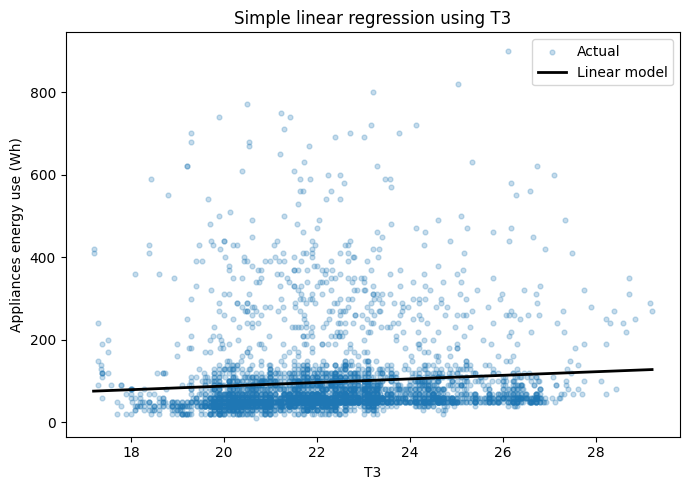

In [106]:
fig, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.scatter(X_test[single_feature], y_test, s=12, alpha=0.25, label="Actual")

order = np.argsort(X_test[single_feature].to_numpy())
ax.plot(
    X_test[single_feature].to_numpy()[order],
    simple_pred[order],
    color="black",
    linewidth=2,
    label="Linear model",
)

ax.set_xlabel(single_feature)
ax.set_ylabel("Appliances energy use (Wh)")
ax.set_title(f"Simple linear regression using {single_feature}")
ax.legend()
plt.tight_layout()


### Multiple linear regression

Now use all of the physical sensor and time features. This model can combine weak signals from many sensors.


In [103]:
multi_lr = LinearRegression()
multi_lr.fit(X_train, y_train)

multi_pred = multi_lr.predict(X_test)
multi_report = regression_report("Multiple linear regression", y_test, multi_pred)
multi_report


{'model': 'Multiple linear regression',
 'MAE': 52.57965045065556,
 'RMSE': 91.10890778036533,
 'R2': 0.1705048950882161}

In [104]:
coef_table = pd.DataFrame({
    "feature": feature_columns,
    "coefficient": multi_lr.coef_,
})
coef_table["abs_coefficient"] = coef_table["coefficient"].abs()
coef_table.sort_values("abs_coefficient", ascending=False).head(10)


,feature,coefficient,abs_coefficient
5,T3,26.646236,26.646236
3,T2,-18.066899,18.066899
2,RH_1,15.235137,15.235137
4,RH_2,-13.447616,13.447616
17,T9,-12.726846,12.726846
19,T_out,-10.700222,10.700222
11,T6,7.859966,7.859966
15,T8,5.979497,5.979497
6,RH_3,4.490369,4.490369
24,Tdewpoint,3.915071,3.915071


The multiple linear regression model usually improves over a one-feature model, but the R² is still modest. That is a useful teaching point: IoT sensor data can be noisy and incomplete. The sensors do not directly tell us which appliance is running or what people in the home are doing.


<a class="anchor" id="sixth-bullet"></a>
## 6 - K-nearest neighbors regression

KNN regression predicts a test point by finding similar training points and averaging their target values. Because KNN uses distances, feature scaling matters. We will use a `Pipeline` that first standardizes each feature and then applies KNN.


In [107]:
knn_k = 5

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=knn_k),
)
knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)
knn_report = regression_report(f"KNN regression (k={knn_k})", y_test, knn_pred)
knn_report


{'model': 'KNN regression (k=5)',
 'MAE': 34.046617684317205,
 'RMSE': 73.2733376587584,
 'R2': 0.46348224861868004}

In [108]:
k_values = [1, 3, 5, 11, 21, 51]
knn_results = []

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=k),
    )
    model.fit(X_train, y_train)
    test_pred = model.predict(X_test)
    knn_results.append({
        "k": k,
        "train_R2": model.score(X_train, y_train),
        **regression_report(f"KNN k={k}", y_test, test_pred),
    })

knn_results_df = pd.DataFrame(knn_results)
knn_results_df


,k,train_R2,model,MAE,RMSE,R2
0,1,1.000000,KNN k=1,30.932354,76.806180,0.410499
1,3,0.778860,KNN k=3,31.423866,70.516032,0.503101
2,5,0.657799,KNN k=5,34.046618,73.273338,0.463482
3,11,0.507938,KNN k=11,38.642698,78.792093,0.379621
4,21,0.417419,KNN k=21,41.371023,81.478907,0.336589
5,51,0.309612,KNN k=51,44.588593,85.356644,0.271941


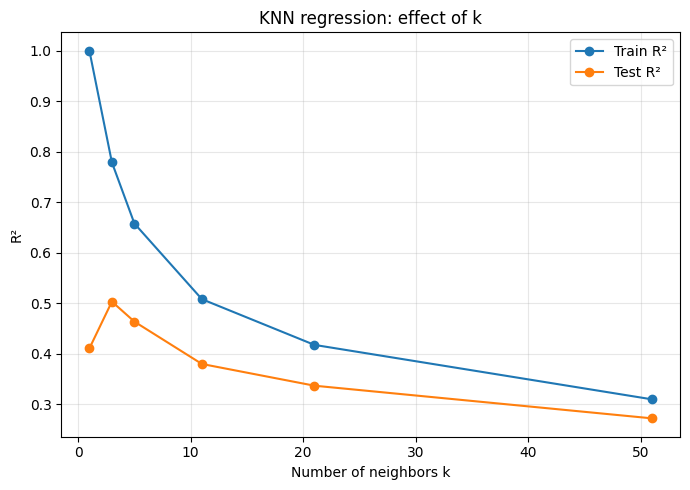

In [109]:
fig, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.plot(knn_results_df["k"], knn_results_df["train_R2"], marker="o", label="Train R²")
ax.plot(knn_results_df["k"], knn_results_df["R2"], marker="o", label="Test R²")
ax.set_xlabel("Number of neighbors k")
ax.set_ylabel("R²")
ax.set_title("KNN regression: effect of k")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()


A very small `k` can overfit because each prediction is based on only one or a few nearby training samples. A larger `k` smooths the prediction, but if `k` is too large, the model underfits by averaging over many unlike situations.


### Model comparison


In [110]:
model_results = pd.DataFrame([simple_report, multi_report, knn_report])
model_results


,model,MAE,RMSE,R2
0,Linear regression (T3),59.491326,99.668545,0.007322
1,Multiple linear regression,52.579650,91.108908,0.170505
2,KNN regression (k=5),34.046618,73.273338,0.463482


### Expected takeaways

1. The single-feature linear model is interpretable, but it misses most of the structure in the data.
2. Multiple linear regression uses more sensor information and usually improves the error metrics.
3. KNN can perform better because it can model local nonlinear patterns, but it is less interpretable and depends strongly on feature scaling and the choice of `k`.
4. The prediction is not perfect because appliance use is driven by unobserved behavior: occupancy, cooking, laundry, device usage, and other activities are not directly measured.
